## 1. Open the project files

**Note for lectuerer:** Please can you download the project ZIP from my GitHub repository. Run this cell, click Choose Files, and select the ZIP. Then run the remaining cells in order. The zip file is called: **CRM_Final_final.zip**

In [54]:
from pathlib import Path
from io import BytesIO, StringIO
import os, zipfile

if Path("CRM Final/data").exists():
    os.chdir("CRM Final")
if not Path("data").exists():
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError("Open the notebook inside the extracted CRM Final folder.")
    uploaded = files.upload()
    for name, content in uploaded.items():
        if name.lower().endswith(".zip"):
            with zipfile.ZipFile(BytesIO(content)) as package:
                package.extractall("/content")
    os.chdir("/content/CRM Final")
print("Project files ready.")


## 2. Import the libraries



In [28]:
import json, hashlib, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from scipy.optimize import linear_sum_assignment
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from IPython.display import display
from importlib.metadata import version
from threadpoolctl import threadpool_limits
threadpool_limits(1)
for folder in ["outputs", "figures"]:
    Path(folder).mkdir(exist_ok=True)


## 3. Read the S&P 500 list



In [29]:
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
table = pd.read_html(StringIO(Path("data/constituents_source.html").read_text()))
sp500_df = table[0]

tickers = sp500_df['Symbol'].tolist()
tickers = [t.replace('.', '-') for t in tickers]

print('Total tickers extracted:', len(tickers))
sp500_df[['Symbol', 'Security', 'GICS Sector']].head(10)
sp500_df["Share"] = tickers
retrieval = json.loads(Path("data/acquisition_manifest.json").read_text())
print("Retrieved:", retrieval["retrieved_utc"])


Total tickers extracted: 503
Retrieved: 2026-11-17T17:04:31.485617+00:00


## 4. Load the saved yfinance data



In [30]:
records = json.loads(Path("data/download_log.json").read_text())
histories = {}
metadata = {}
for record in records:
    share = record["symbol"]
    metadata[share] = record
    if record["status"] == "downloaded":
        path = Path(record["file"])
        assert record["source"] == "Yahoo Finance via yfinance"
        assert record["parameters"]["start"] == "2021-01-01"
        assert record["parameters"]["end"] == "2025-01-01"
        assert hashlib.sha256(path.read_bytes()).hexdigest() == record["sha256"]
        histories[share] = pd.read_csv(path, index_col="Date", parse_dates=True).sort_index()
calendar = histories["^GSPC"].index
assert not calendar.has_duplicates
assert metadata["^GSPC"].get("currency") == "USD"
observation_date = calendar[-1]
print("Observation date:", observation_date.date())
print("Daily benchmark sessions:", len(calendar))


Observation date: 2024-12-31
Daily benchmark sessions: 1005


## 5. Check the histories



In [31]:
price_columns = ["Open", "High", "Low", "Close", "Adj Close"]
validation = []
for share in tickers:
    reasons = []
    if share not in histories:
        reasons.append("unavailable study-period history (download failed)")
    else:
        data = histories[share]
        if data.index.has_duplicates:
            reasons.append("duplicate_dates")
        if len(calendar.difference(data.index)):
            reasons.append("missing_sessions")
        if len(data.index.difference(calendar)):
            reasons.append("extra_sessions")
        if (~np.isfinite(data[price_columns]) | data[price_columns].le(0)).any().any():
            reasons.append("invalid_prices")
        volume = data["Volume"]
        if (~np.isfinite(volume) | volume.le(0) | volume.mod(1).ne(0)).any():
            reasons.append("invalid_volume")
        if metadata[share].get("currency") != "USD":
            reasons.append("invalid_currency")
    validation.append({"ticker": share, "status": "excluded" if reasons else "included",
                       "reason": "; ".join(reasons)})
validation_log = pd.DataFrame(validation)
valid_shares = validation_log.loc[validation_log["status"] == "included", "ticker"].tolist()
validation_log.to_csv("outputs/validation_log.csv", index=False)
print("Included:", len(valid_shares), "Excluded:", len(tickers) - len(valid_shares))
display(validation_log.loc[validation_log["status"] == "excluded"])


Included: 486 Excluded: 17


,ticker,status,reason
40,APP,excluded,missing_sessions
116,COIN,excluded,missing_sessions
123,CEG,excluded,missing_sessions
181,EXE,excluded,missing_sessions
192,FDXF,excluded,unavailable study-period history (download fai...
193,FERG,excluded,invalid_volume
210,GEHC,excluded,missing_sessions
211,GEV,excluded,missing_sessions
233,HONA,excluded,unavailable study-period history (download fai...
379,Q,excluded,unavailable study-period history (download fai...


## 6. Calculate weekly returns

In [32]:
import pandas as pd

def calculate_weekly_returns(df1, shares=None):

    prices = df1 if shares is None else df1.loc[shares]

    prices = prices.T.copy()
    prices.index = pd.to_datetime(prices.index)
    prices = prices.sort_index()

    weekly_prices = prices.resample("W-FRI").last()
    complete = ((weekly_prices.index - pd.Timedelta(days=4)) >= pd.Timestamp("2021-01-01"))
    complete = complete & (weekly_prices.index < pd.Timestamp("2025-01-01"))
    weekly_prices = weekly_prices.loc[complete]
    return weekly_prices.pct_change(fill_method=None)
df = pd.DataFrame({share: histories[share]["Adj Close"] for share in valid_shares}).reindex(calendar)

df1 = df.T

print('Shape after transpose:', df1.shape)
df1

weekly_returns = calculate_weekly_returns(df1)
market_prices = histories["^GSPC"]["Adj Close"].to_frame("^GSPC")
market_weekly_returns = calculate_weekly_returns(market_prices.T)
market_returns = market_weekly_returns["^GSPC"]
assert weekly_returns.index.equals(market_returns.index)
print("Aligned weekly returns:", market_returns.notna().sum())


Shape after transpose: (486, 1005)
Aligned weekly returns: 207


## 7. Calculate weekly beta


In [33]:
import pandas as pd
import numpy as np

def calculate_weekly_beta(weekly_returns, market_returns, min_weeks=52):

    if min_weeks < 2:
        raise ValueError("min_weeks must be at least 2.")

    results = []

    for share in weekly_returns.columns:
        paired = pd.concat(
            [weekly_returns[share].rename("share"),
             market_returns.rename("market")],
            axis=1
        ).replace([np.inf, -np.inf], np.nan).dropna()

        variance = paired["market"].var(ddof=1)
        beta = np.nan

        if len(paired) >= min_weeks and variance > 0:
            beta = paired["share"].cov(paired["market"]) / variance

        results.append({
            "Share": share,
            "Beta": beta,
            "Paired_weeks": len(paired)
        })

    return pd.DataFrame(
        results, columns=["Share", "Beta", "Paired_weeks"]
    ).set_index("Share")

beta_df = calculate_weekly_beta(
    weekly_returns,
    market_weekly_returns["^GSPC"]
)

beta_df.head()

,Beta,Paired_weeks
Share,,
MMM,0.869079,207
AOS,1.042804,207
ABT,0.583542,207
ABBV,0.425366,207
ACN,1.143301,207


In [34]:
combined_df = (
    weekly_returns
    .rename_axis(index="Week", columns="Share")
    .reset_index()
    .melt(
        id_vars="Week",
        var_name="Share",
        value_name="Weekly_Return"
    )
    .join(beta_df[["Beta"]], on="Share")
    .sort_values(["Share", "Week"])
    .reset_index(drop=True)
)

combined_df

,Week,Share,Weekly_Return,Beta
0,2021-01-08,A,NaN,1.074724
1,2021-01-15,A,-0.006690,1.074724
2,2021-01-22,A,0.000951,1.074724
3,2021-01-29,A,-0.048761,1.074724
4,2021-02-05,A,0.025048,1.074724
...,...,...,...,...
101083,2024-11-29,ZTS,-0.009663,0.979782
101084,2024-12-06,ZTS,0.006904,0.979782
101085,2024-12-13,ZTS,0.009747,0.979782
101086,2024-12-20,ZTS,-0.074868,0.979782


In [35]:
print("Null values per column:")
print(combined_df.isna().sum())

rows_before = len(combined_df)
combined_df = combined_df.dropna().reset_index(drop=True)

print("Rows removed:", rows_before - len(combined_df))
print("Rows remaining:", len(combined_df))
combined_df.to_csv("outputs/weekly_return_evidence.csv", index=False)
risk_return = combined_df.groupby("Share").agg(
    Mean_Weekly_Return=("Weekly_Return", "mean"), Beta=("Beta", "first"))
risk_return.head()


Null values per column:
Week               0
Share              0
Weekly_Return    486
Beta               0
dtype: int64
Rows removed: 486
Rows remaining: 100602


,Mean_Weekly_Return,Beta
Share,,
A,0.001121,1.074724
AAPL,0.003930,1.174836
ABBV,0.003749,0.425366
ABNB,0.001475,1.472709
ABT,0.000971,0.583542


## 8. Calculate trading activity RFM



In [36]:
import pandas as pd

shares = valid_shares

results = []

for ticker in shares:
    try:
        data = histories[ticker].copy()

        if data.empty:
            print(f"{ticker}: no data downloaded")
            continue

        data = data.sort_index()

        average_volume = data["Volume"].shift(1).rolling(20).mean()

        data["HighVolume"] = data["Volume"] > 2 * average_volume

        valid = data.loc[average_volume.notna()].copy()

        if len(valid) < 60:
            print(f"{ticker}: insufficient history")
            continue

        recent = valid.tail(60)
        high_volume_days = valid.loc[valid["HighVolume"]]

        recency = (
            (valid.index[-1].date() - high_volume_days.index[-1].date()).days
            if not high_volume_days.empty
            else None
        )

        results.append({
            "Share": ticker,
            "AsOf": valid.index[-1].date(),
            "Recency": recency,
            "Frequency": int(recent["HighVolume"].sum()),
            "Monetary": round(
                (recent["Close"] * recent["Volume"]).sum(), 2
            )
        })

    except Exception as error:
        print(f"{ticker}: {error}")

output = pd.DataFrame(
    results,
    columns=["Share", "AsOf", "Recency", "Frequency", "Monetary"]
)

output["Recency"] = output["Recency"].astype("Int64")

display(output.head(10))
output.to_csv("outputs/rfm_all_shares.csv", index=False)
customers = output.set_index("Share")
share_table = risk_return.join(customers[ ["Recency", "Frequency", "Monetary"] ]).dropna().sort_index()
share_table["observation_date"] = str(observation_date.date())
share_table["sector"] = sp500_df.set_index("Share").loc[share_table.index, "GICS Sector"]
share_table["security"] = sp500_df.set_index("Share").loc[share_table.index, "Security"]
share_table["n_weekly"] = beta_df.loc[share_table.index, "Paired_weeks"]
missing = validation_log["status"].eq("included") & ~validation_log["ticker"].isin(share_table.index)
validation_log.loc[missing, ["status", "reason"]] = ["excluded", "missing RFM or risk/return feature"]
validation_log.to_csv("outputs/validation_log.csv", index=False)
print("Common shares:", len(share_table))
share_table.head()


,Share,AsOf,Recency,Frequency,Monetary
0,MMM,2024-12-31,11,4,2.599146e+10
1,AOS,2024-12-31,11,2,4.748980e+09
2,ABT,2024-12-31,11,1,3.523027e+10
3,ABBV,2024-12-31,11,3,6.837054e+10
4,ACN,2024-12-31,11,2,5.199430e+10
5,ADBE,2024-12-31,18,3,1.030403e+11
6,AMD,2024-12-31,18,4,3.131659e+11
7,AES,2024-12-31,54,3,1.119578e+10
8,AFL,2024-12-31,11,2,1.328456e+10
9,A,2024-12-31,11,2,1.400180e+10


Common shares: 486


,Mean_Weekly_Return,Beta,Recency,Frequency,Monetary,observation_date,sector,security,n_weekly
Share,,,,,,,,,
A,0.001121,1.074724,11,2,1.400180e+10,2024-12-31,Health Care,Agilent Technologies,207
AAPL,0.003930,1.174836,11,2,6.233034e+11,2024-12-31,Information Technology,Apple Inc.,207
ABBV,0.003749,0.425366,11,3,6.837054e+10,2024-12-31,Health Care,AbbVie,207
ABNB,0.001475,1.472709,11,3,3.652850e+10,2024-12-31,Consumer Discretionary,Airbnb,207
ABT,0.000971,0.583542,11,1,3.523027e+10,2024-12-31,Health Care,Abbott Laboratories,207


## 9. Check distributions and prepare the inputs


In [37]:
rfm_columns = ["Recency", "Frequency", "Monetary"]
customers = share_table[rfm_columns].rename(columns={"Monetary": "MonetaryValue"}).copy()
display(share_table[["Mean_Weekly_Return", "Beta"] + rfm_columns].describe().T)
print("Raw skew:")
print(customers.skew())


,count,mean,std,min,25%,50%,75%,max
Mean_Weekly_Return,486.0,0.002857,0.002652,-0.004468,0.001182,0.002619,0.004207,0.017772
Beta,486.0,0.973695,0.407339,0.055453,0.6666,0.95061,1.179538,3.77856
Recency,486.0,20.407407,21.342438,4.0,11.0,11.0,14.75,222.0
Frequency,486.0,2.989712,1.3308,0.0,2.0,3.0,4.0,8.0
Monetary,486.0,39404191889.207779,129138833232.971375,1297482617.05,10195173392.272499,16683821504.625,32276893043.872498,1847697379221.840088


Raw skew:
Recency           3.645784
Frequency         0.424735
MonetaryValue    11.683797
dtype: Float64


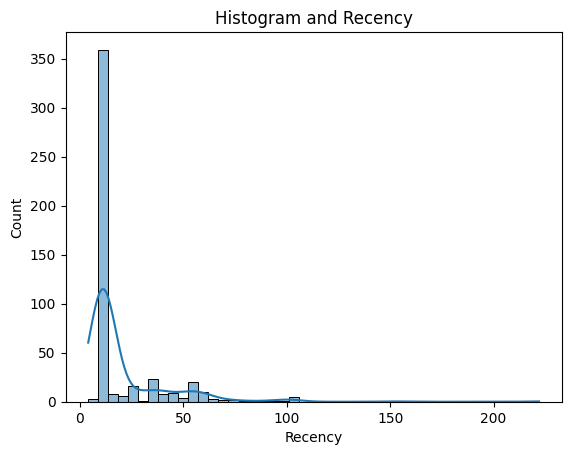

In [38]:
import seaborn as sns
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
sns.histplot(data=customers, x='Recency', kde=True)
ax.set_title('Histogram and Recency')
plt.show()


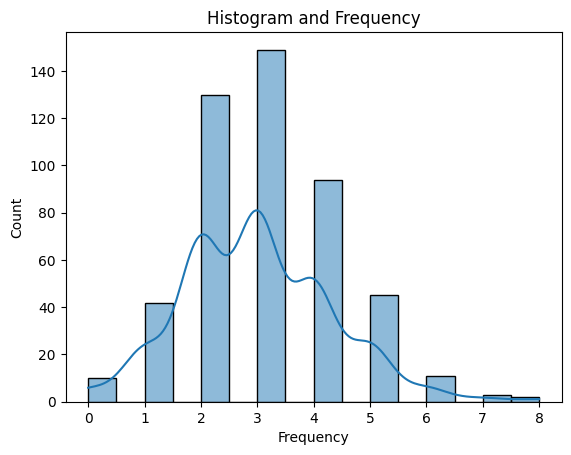

In [39]:
import seaborn as sns
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
sns.histplot(data=customers, x='Frequency', kde=True)
ax.set_title('Histogram and Frequency')
plt.show()


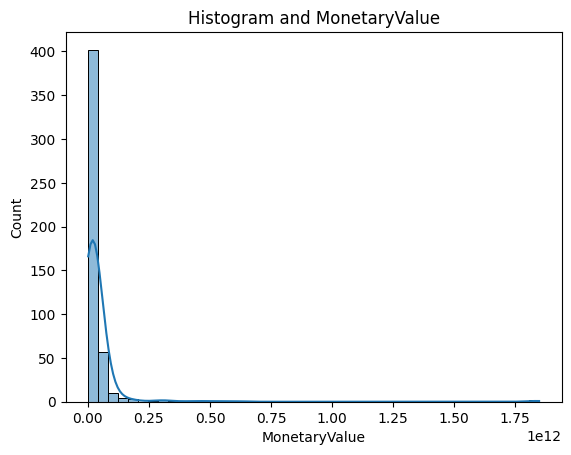

In [40]:
import seaborn as sns
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
sns.histplot(data=customers, x='MonetaryValue', kde=True)
ax.set_title('Histogram and MonetaryValue')
plt.show()


In [41]:
customers_fix = pd.DataFrame()
customers_fix["Recency"] = np.log1p(customers['Recency'])
customers_fix["Frequency"] = customers['Frequency']
customers_fix["MonetaryValue"] = np.log1p(customers['MonetaryValue'])
customers_fix.tail()

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaler.fit(customers_fix)
customers_normalized = scaler.transform(customers_fix)

print(customers_normalized.mean(axis = 0).round(2))
print(customers_normalized.std(axis = 0).round(2))
print("Transformed skew:")
print(customers_fix.skew())
risk_values = share_table[["Mean_Weekly_Return", "Beta"]]
risk_normalized = StandardScaler().fit_transform(risk_values)
customers_fix.corr().to_csv("outputs/model_input_correlations.csv")
share_table[["Mean_Weekly_Return", "Beta"] + rfm_columns].describe().T.to_csv("outputs/feature_summary.csv")


[-0. -0. -0.]
[1. 1. 1.]
Transformed skew:
Recency          1.583201
Frequency        0.424735
MonetaryValue    1.079057
dtype: Float64


## 10. Compare cluster counts


In [42]:
def compare_clusters(values, original, method):
    scores, profiles, solutions = [], [], {}
    if method == "ward":
        tree = linkage(values, method="ward")
    for k in range(2, 9):
        if method == "ward":
            labels = cut_tree(tree, n_clusters=k).ravel()
            inertia = np.nan
        else:
            model = KMeans(n_clusters=k, random_state=42, n_init=50).fit(values)
            labels, inertia = model.labels_, model.inertia_
        sizes = np.bincount(labels).tolist()
        scores.append({"k": k, "silhouette": silhouette_score(values, labels),
                       "inertia": inertia, "sizes": sizes})
        profiles.append(original.assign(Cluster=labels + 1).groupby("Cluster").mean().assign(k=k))
        solutions[k] = labels + 1
    scores = pd.DataFrame(scores)
    best_k = int(scores.loc[scores["silhouette"].idxmax(), "k"])
    return solutions[best_k], scores, pd.concat(profiles).reset_index()

risk_ward, rw_scores, rw_profiles = compare_clusters(risk_normalized, risk_values, "ward")
risk_kmeans, rk_scores, rk_profiles = compare_clusters(risk_normalized, risk_values, "kmeans")
rfm_ward, fw_scores, fw_profiles = compare_clusters(customers_normalized, share_table[rfm_columns], "ward")
rfm_kmeans, fk_scores, fk_profiles = compare_clusters(customers_normalized, share_table[rfm_columns], "kmeans")


## 11. Inspect the model comparisons


In [43]:
names = ["risk_return_ward", "risk_return_kmeans", "rfm_ward", "rfm_kmeans"]
labels = [risk_ward, risk_kmeans, rfm_ward, rfm_kmeans]
score_tables = [rw_scores, rk_scores, fw_scores, fk_scores]
profile_tables = [rw_profiles, rk_profiles, fw_profiles, fk_profiles]
diagnostics, candidates = [], []
for name, scores, profiles in zip(names, score_tables, profile_tables):
    space, method = name.rsplit("_", 1)
    diagnostics.append(scores.assign(space=space, method=method))
    candidates.append(profiles.assign(space=space, method=method))
    print(name)
    display(scores)
    print("Selected cluster sizes:", pd.Series(labels[names.index(name)]).value_counts().sort_index().to_dict())
diagnostics = pd.concat(diagnostics, ignore_index=True)
diagnostics.to_csv("outputs/model_diagnostics.csv", index=False)
pd.concat(candidates, ignore_index=True).to_csv("outputs/candidate_profiles_all_k.csv", index=False)


risk_return_ward


,k,silhouette,inertia,sizes
0,2,0.339485,NaN,"[394, 92]"
1,3,0.273834,NaN,"[230, 92, 164]"
2,4,0.282115,NaN,"[182, 92, 164, 48]"
3,5,0.304135,NaN,"[182, 92, 98, 48, 66]"
4,6,0.320409,NaN,"[182, 87, 98, 48, 66, 5]"
5,7,0.323951,NaN,"[160, 87, 98, 48, 66, 22, 5]"
6,8,0.320779,NaN,"[160, 56, 98, 48, 66, 22, 31, 5]"


Selected cluster sizes: {1: 394, 2: 92}
risk_return_kmeans


,k,silhouette,inertia,sizes
0,2,0.386950,621.634386,"[143, 343]"
1,3,0.328907,461.178718,"[119, 202, 165]"
2,4,0.326103,371.571229,"[160, 41, 132, 153]"
3,5,0.338131,309.959968,"[165, 114, 28, 124, 55]"
4,6,0.326443,265.707201,"[56, 20, 134, 76, 115, 85]"
5,7,0.329204,227.238608,"[78, 47, 5, 84, 105, 126, 41]"
6,8,0.354242,194.249434,"[78, 80, 5, 40, 29, 135, 43, 76]"


Selected cluster sizes: {1: 143, 2: 343}
rfm_ward


,k,silhouette,inertia,sizes
0,2,0.402044,NaN,"[380, 106]"
1,3,0.335170,NaN,"[239, 141, 106]"
2,4,0.292533,NaN,"[169, 141, 70, 106]"
3,5,0.285990,NaN,"[169, 84, 57, 70, 106]"
4,6,0.276030,NaN,"[169, 84, 57, 70, 70, 36]"
5,7,0.296944,NaN,"[169, 14, 70, 57, 70, 70, 36]"
6,8,0.299019,NaN,"[66, 14, 70, 57, 70, 70, 103, 36]"


Selected cluster sizes: {1: 380, 2: 106}
rfm_kmeans


,k,silhouette,inertia,sizes
0,2,0.415400,999.520393,"[102, 384]"
1,3,0.343037,742.493330,"[139, 90, 257]"
2,4,0.361713,559.243771,"[120, 194, 82, 90]"
3,5,0.348176,480.744042,"[40, 119, 87, 141, 99]"
4,6,0.345339,421.186670,"[113, 139, 38, 30, 70, 96]"
5,7,0.339993,377.531674,"[68, 148, 20, 94, 80, 30, 46]"
6,8,0.338260,342.209343,"[131, 70, 22, 66, 57, 69, 27, 44]"


Selected cluster sizes: {1: 102, 2: 384}


## 12. Plot the dendrograms


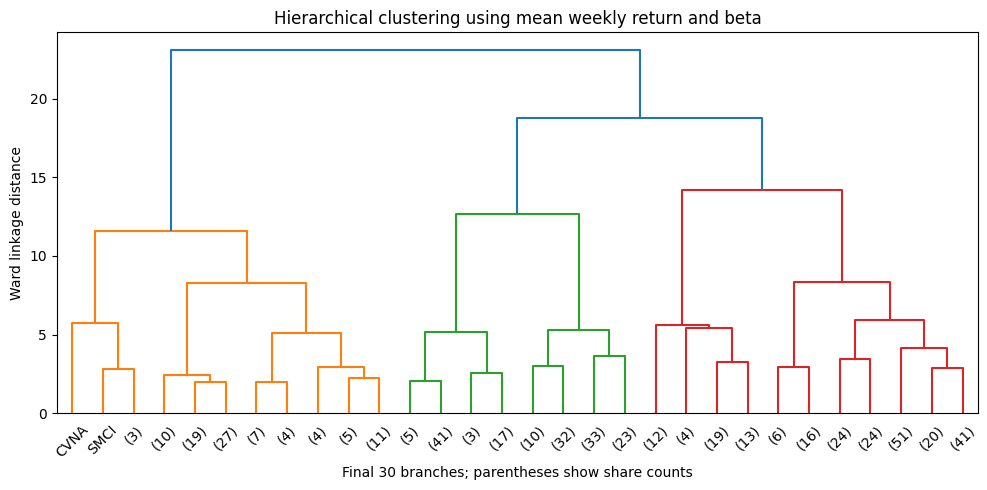

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from sklearn.preprocessing import StandardScaler

data1 = share_table.reset_index()
features = ["Mean_Weekly_Return", "Beta"]
data1[features] = data1[features].apply(pd.to_numeric, errors="coerce")
data1 = data1.replace([np.inf, -np.inf], np.nan)
data1 = data1.dropna(subset=features).copy()
X_scaled = StandardScaler().fit_transform(data1[features])

hierarchy = linkage(X_scaled, method="ward")

plt.figure(figsize=(10, 5))
dendrogram(
    hierarchy,
    labels=data1["Share"].tolist(),
    leaf_rotation=45, truncate_mode="lastp", p=30, show_leaf_counts=True
)
plt.title("Hierarchical clustering using mean weekly return and beta")
plt.xlabel("Final 30 branches; parentheses show share counts")
plt.ylabel("Ward linkage distance")
plt.tight_layout()
plt.savefig("figures/risk_return_dendrogram.png", dpi=150)
plt.show()



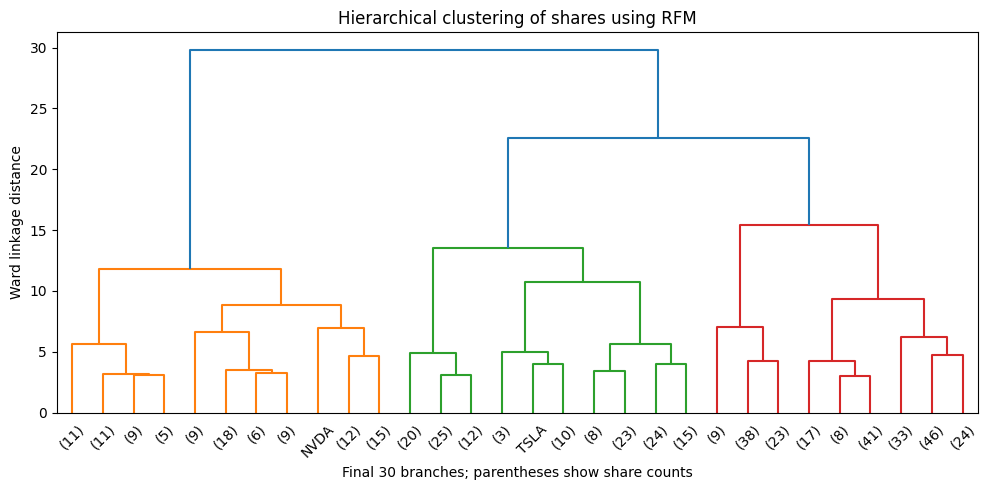


Cluster averages in original units:
         Recency  Frequency      Monetary
Cluster                                  
1          11.47       3.16  3.866901e+10
2          52.43       2.40  4.203975e+10


In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from sklearn.preprocessing import StandardScaler

data = share_table.reset_index()
features = ["Recency", "Frequency", "Monetary"]
X = data[features].copy()
X["Monetary"] = np.log1p(X["Monetary"])
X["Recency"] = np.log1p(X["Recency"])
X_scaled = StandardScaler().fit_transform(X)
hierarchy = linkage(X_scaled, method="ward")

plt.figure(figsize=(10, 5))
dendrogram(
    hierarchy,
    labels=data["Share"].tolist(),
    leaf_rotation=45, truncate_mode="lastp", p=30, show_leaf_counts=True
)
plt.title("Hierarchical clustering of shares using RFM")
plt.xlabel("Final 30 branches; parentheses show share counts")
plt.ylabel("Ward linkage distance")
plt.tight_layout()
plt.savefig("figures/rfm_dendrogram.png", dpi=150)
plt.show()


k_rfm = len(np.unique(rfm_ward))
data["Cluster"] = (
    cut_tree(hierarchy, n_clusters=k_rfm).ravel() + 1
)
print("\nCluster averages in original units:")
print(data.groupby("Cluster")[features].mean().round(2))


## 13. Compare profiles and plot the groups


risk_return_ward


Mean_Weekly_Return                      Beta            \
                              count      mean    median count      mean   
risk_return_ward                                                          
1                               394  0.002048  0.002093   394  0.897950   
2                                92  0.006321  0.005503    92  1.298084   

                           Recency                   Frequency            \
                    median   count       mean median     count      mean   
risk_return_ward                                                           
1                 0.881695     394   19.64467   11.0       394  2.941624   
2                 1.217711      92  23.673913   11.0        92  3.195652   

                        Monetary                              
                 median    count          mean        median  
risk_return_ward                                              
1                   3.0      394  3.020963e+10  1.532516e+10  
2                   3.0       92  7.878092e+10  2.418413e+10

risk_return_kmeans


Mean_Weekly_Return                      Beta            \
                                count      mean    median count      mean   
risk_return_kmeans                                                          
1                                 143  0.005330  0.004861   143  1.350487   
2                                 343  0.001826  0.001917   343  0.816607   

                             Recency                   Frequency            \
                      median   count       mean median     count      mean   
risk_return_kmeans                                                           
1                   1.278113     143  22.636364   11.0       143  3.146853   
2                   0.833991     343  19.478134   11.0       343  2.924198   

                          Monetary                              
                   median    count          mean        median  
risk_return_kmeans                                              
1                     3.0      143  8.143839e+10  2.552367e+10  
2                     3.0      343  2.187973e+10  1.420560e+10

rfm_ward


Mean_Weekly_Return                      Beta                      \
                      count      mean    median count      mean    median   
rfm_ward                                                                    
1                       380  0.002819  0.002608   380  0.956704  0.933619   
2                       106  0.002996  0.002625   106  1.034607  1.053557   

         Recency                   Frequency                  Monetary  \
           count       mean median     count      mean median    count   
rfm_ward                                                                 
1            380  11.473684   11.0       380  3.155263    3.0      380   
2            106  52.433962   46.5       106  2.396226    2.0      106   

                                      
                  mean        median  
rfm_ward                              
1         3.866901e+10  1.547309e+10  
2         4.203975e+10  1.948502e+10

rfm_kmeans


Mean_Weekly_Return                      Beta                      \
                        count      mean    median count      mean    median   
rfm_kmeans                                                                    
1                         102  0.003137  0.002625   102  1.061049  1.062901   
2                         384  0.002783  0.002608   384  0.950492  0.932474   

           Recency                   Frequency                  Monetary  \
             count       mean median     count      mean median    count   
rfm_kmeans                                                                 
1              102  53.666667   49.0       102  2.294118    2.0      102   
2              384  11.572917   11.0       384  3.174479    3.0      384   

                                        
                    mean        median  
rfm_kmeans                              
1           6.447379e+10  2.118345e+10  
2           3.274508e+10  1.526242e+10

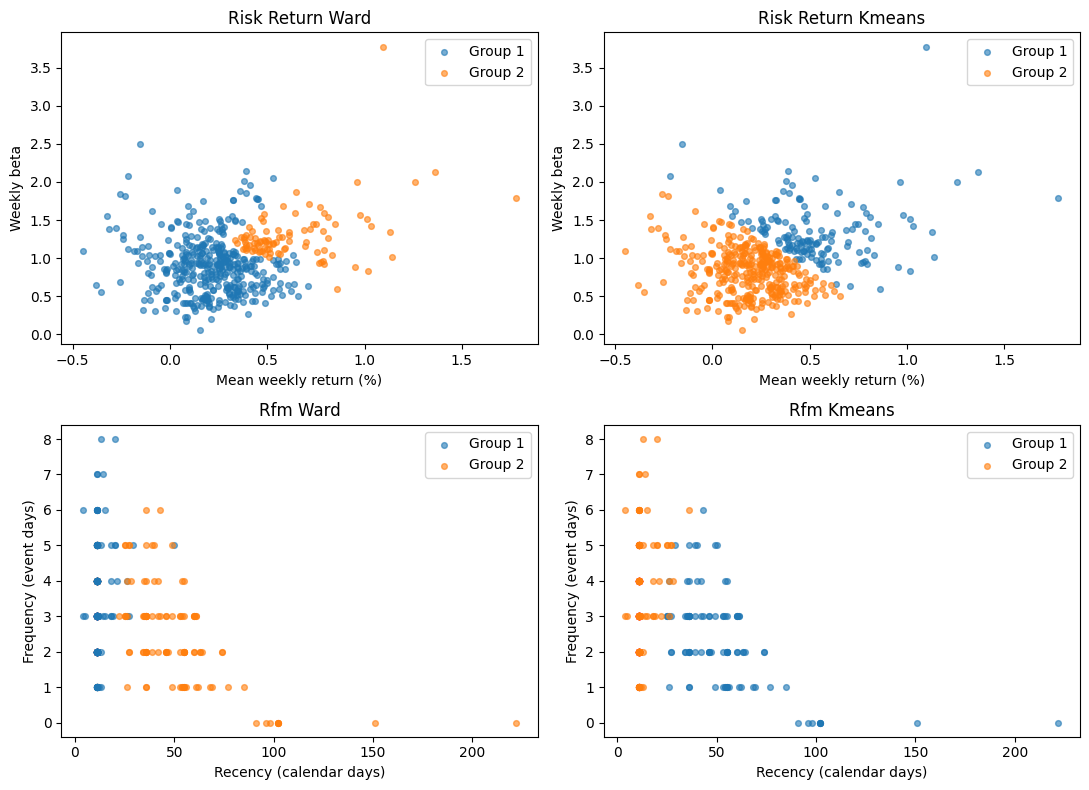

Risk/return algorithm ARI: 0.59755503175211
RFM algorithm ARI: 0.8920163524760355


In [46]:
metric_columns = ["Mean_Weekly_Return", "Beta", "Recency", "Frequency", "Monetary"]
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for i, (name, groups) in enumerate(zip(names, labels)):
    share_table[name] = groups
    profile = share_table.groupby(name)[metric_columns].agg(["count", "mean", "median"])
    profile.to_csv("outputs/" + name + "_profiles.csv")
    print(name)
    display(profile)
    ax = axes.ravel()[i]
    x = share_table["Mean_Weekly_Return"] * 100 if i < 2 else share_table["Recency"]
    y = share_table["Beta"] if i < 2 else share_table["Frequency"]
    for group in sorted(np.unique(groups)):
        ax.scatter(x[groups == group], y[groups == group], s=17, alpha=.6, label=f"Group {group}")
    ax.set_title(name.replace("_", " ").title())
    ax.set_xlabel("Mean weekly return (%)" if i < 2 else "Recency (calendar days)")
    ax.set_ylabel("Weekly beta" if i < 2 else "Frequency (event days)")
    ax.legend()
plt.tight_layout()
plt.savefig("figures/baseline_clusters.png", dpi=150)
plt.show()
print("Risk/return algorithm ARI:", adjusted_rand_score(risk_ward, risk_kmeans))
print("RFM algorithm ARI:", adjusted_rand_score(rfm_ward, rfm_kmeans))


## 14. Check correlations and remove Monetary


In [47]:
correlations = share_table[rfm_columns].copy()
correlations["Monetary"] = np.log1p(correlations["Monetary"])
correlations = correlations.rename(columns={"Monetary": "log1p_M"}).corr()
correlations.to_csv("outputs/rfm_correlations.csv")
display(correlations)
k_rfm = len(np.unique(rfm_ward))
reduced = customers_fix[["Recency", "Frequency"]]
reduced_scaled = StandardScaler().fit_transform(reduced)
rf_labels = cut_tree(linkage(reduced_scaled, method="ward"), n_clusters=k_rfm).ravel() + 1
monetary_ari = adjusted_rand_score(rfm_ward, rf_labels)
membership = pd.crosstab(rfm_ward, rf_labels)
rows, columns = linear_sum_assignment(-membership.to_numpy())
changed = len(share_table) - membership.to_numpy()[rows, columns].sum()
share_table["rf_reduced_ward"] = rf_labels
print("Monetary-removal ARI:", monetary_ari)
print("Changed memberships after matching:", changed)
display(membership)
display(share_table.groupby("rf_reduced_ward")[rfm_columns].agg(["count", "mean", "median"]))
membership.to_csv("outputs/monetary_removal_membership.csv")


,Recency,Frequency,log1p_M
Recency,1.000000,-0.346344,0.152394
Frequency,-0.346344,1.000000,0.012782
log1p_M,0.152394,0.012782,1.000000


Monetary-removal ARI: 0.884599082156261
Changed memberships after matching: 13


col_0,1,2
row_0,,
1,372,8
2,5,101


Recency                   Frequency                  Monetary  \
                  count       mean median     count      mean median    count   
rf_reduced_ward                                                                 
1                   377  11.355438   11.0       377  3.122016    3.0      377   
2                   109  51.715596   46.0       109  2.532110    2.0      109   

                                             
                         mean        median  
rf_reduced_ward                              
1                3.144350e+10  1.533472e+10  
2                6.693795e+10  2.084781e+10

## 15. Compare sector composition


sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
risk_return_ward,,,,,,,,,,,
1,3.8,9.1,8.1,4.1,15.5,14.2,14.5,11.4,5.1,6.9,7.4
2,5.4,12.0,0.0,4.3,14.1,2.2,22.8,31.5,3.3,3.3,1.1


sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
rfm_ward,,,,,,,,,,,
1,4.2,9.2,6.3,4.5,15.5,12.4,17.6,13.2,3.9,7.9,5.3
2,3.8,11.3,7.5,2.8,14.2,10.4,10.4,22.6,7.5,0.0,9.4


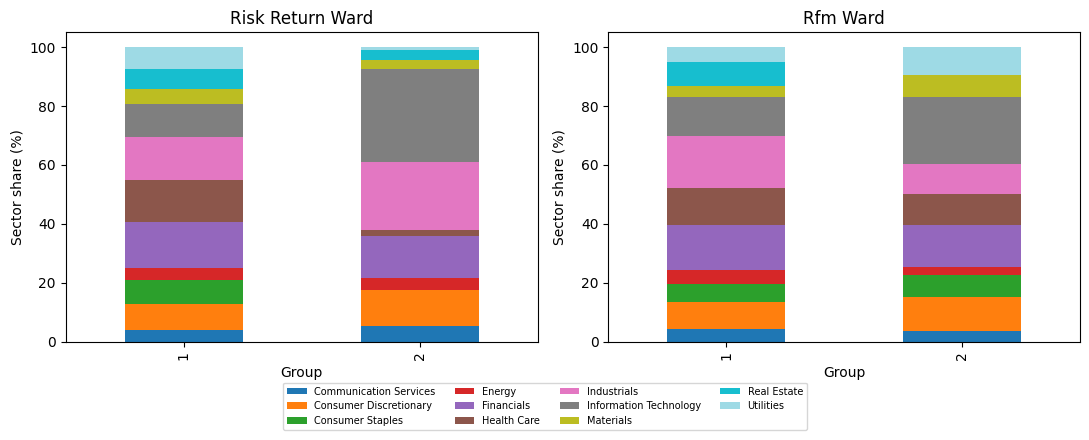

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, ["risk_return_ward", "rfm_ward"]):
    sectors = pd.crosstab(share_table[name], share_table["sector"], normalize="index")
    sectors.to_csv("outputs/" + name + "_sector_proportions.csv")
    display(sectors.mul(100).round(1))
    sectors.mul(100).plot.bar(stacked=True, ax=ax, colormap="tab20", legend=False)
    ax.set_title(name.replace("_", " ").title())
    ax.set_xlabel("Group")
    ax.set_ylabel("Sector share (%)")
handles, sector_names = axes[0].get_legend_handles_labels()
fig.legend(handles, sector_names, loc="lower center", ncol=4, fontsize=7, bbox_to_anchor=(.5, -.1))
plt.tight_layout()
plt.savefig("figures/sector_composition.png", dpi=150, bbox_inches="tight")
plt.show()


## 16. Show a worked RFM example


In [49]:
example = histories["AAPL"][["Close", "Volume"]].copy()
example["preceding_20_mean"] = example["Volume"].shift(1).rolling(20).mean()
example["threshold"] = 2 * example["preceding_20_mean"]
example["qualifies"] = example["Volume"] > example["threshold"]
example["in_final_60"] = example.index.isin(example.index[-60:])
example["daily_traded_value"] = example["Close"] * example["Volume"]
last_event = example.index[example["qualifies"]][-1]
print("Observation date:", observation_date.date())
print("Latest event:", last_event.date())
print("Recency:", (observation_date - last_event).days)
print("Frequency:", example["qualifies"].tail(60).sum())
print("Monetary:", example["daily_traded_value"].tail(60).sum())
display(example.loc[[last_event]])
display(example.tail(10))
example.to_csv("outputs/worked_rfm_trace.csv")


Observation date: 2024-12-31
Latest event: 2024-12-20
Recency: 11
Frequency: 2
Monetary: 623303377706.5842


,Close,Volume,preceding_20_mean,threshold,qualifies,in_final_60,daily_traded_value
Date,,,,,,,
2024-12-20,254.490005,147495300,45004605.0,90009210.0,True,True,3.753608e+10


,Close,Volume,preceding_20_mean,threshold,qualifies,in_final_60,daily_traded_value
Date,,,,,,,
2024-12-17,253.479996,51356400,42354720.0,84709440.0,False,True,1.301782e+10
2024-12-18,248.050003,56774100,42690855.0,85381710.0,False,True,1.408282e+10
2024-12-19,249.789993,60882300,43718970.0,87437940.0,False,True,1.520779e+10
2024-12-20,254.490005,147495300,45004605.0,90009210.0,True,True,3.753608e+10
2024-12-23,255.270004,40858800,50273955.0,100547910.0,False,True,1.043003e+10
2024-12-24,258.200012,23234700,50408480.0,100816960.0,False,True,5.999200e+09
2024-12-26,259.019989,27237100,47062575.0,94125150.0,False,True,7.054953e+09
2024-12-27,255.589996,42355300,46125120.0,92250240.0,False,True,1.082559e+10
2024-12-30,252.199997,35557500,46567965.0,93135930.0,False,True,8.967601e+09


## 17. Check corporate actions


In [50]:
actions, adjustments = [], []
for share in share_table.index:
    data = histories[share]
    ratio = data["Adj Close"] / data["Close"]
    adjustments.append({"ticker": share, "min_adjustment_ratio": ratio.min(),
                        "max_adjustment_ratio": ratio.max()})
    changes = data[["Dividends", "Stock Splits"]].copy()
    changes["close_ratio_to_prior"] = data["Close"] / data["Close"].shift(1)
    changes["volume_ratio_to_prior"] = data["Volume"] / data["Volume"].shift(1)
    changes = changes.loc[changes["Dividends"].gt(0) | changes["Stock Splits"].gt(0)]
    actions.append(changes.assign(ticker=share))
pd.concat(actions).to_csv("outputs/corporate_actions.csv")
pd.DataFrame(adjustments).to_csv("outputs/adjustment_checks.csv", index=False)


## 18. Check the calculations independently


In [51]:
checks = []
for share in share_table.index:
    weekly = histories[share]["Adj Close"].resample("W-FRI").last().loc[weekly_returns.index]
    values = weekly.to_numpy()
    direct_returns = np.array([values[i] / values[i-1] - 1 for i in range(1, len(values))])
    mean_error = abs(direct_returns.mean() - share_table.loc[share, "Mean_Weekly_Return"])
    pair = pd.concat([weekly_returns[share], market_returns], axis=1).dropna()
    slope = np.polyfit(pair.iloc[:, 1], pair.iloc[:, 0], 1)[0]
    beta_error = abs(slope - share_table.loc[share, "Beta"])
    assert mean_error < 1e-12 and beta_error < 1e-10
    checks.append({"ticker": share, "n_weekly": len(pair),
                   "mean_return_error": mean_error, "beta_error": beta_error})
pd.DataFrame(checks).to_csv("outputs/independent_return_checks.csv", index=False)
events = []
for i in range(20, len(example)):
    baseline = sum(example["Volume"].iloc[i-20:i]) / 20
    if example["Volume"].iloc[i] > 2 * baseline:
        events.append(example.index[i])
assert (observation_date - events[-1]).days == share_table.loc["AAPL", "Recency"]
assert sum(date in example.index[-60:] for date in events) == share_table.loc["AAPL", "Frequency"]
manual_monetary = sum(float(p) * float(v) for p, v in
                      zip(example["Close"].tail(60), example["Volume"].tail(60)))
assert np.isclose(manual_monetary, share_table.loc["AAPL", "Monetary"], rtol=1e-12, atol=.01)
print("Calculation checks passed.")


Calculation checks passed.


## 19. Results


In [52]:
rename = {"Mean_Weekly_Return": "mean_weekly_return", "Beta": "weekly_beta",
          "Recency": "R", "Frequency": "F", "Monetary": "M"}
assignments = share_table.rename(columns=rename)
assignments.index.name = "ticker"
assignments.to_csv("outputs/cluster_assignments.csv")
assignments.drop(columns=names + ["rf_reduced_ward"]).to_csv("outputs/features.csv")
summary = {"n_included": len(share_table), "n_excluded": len(tickers) - len(share_table),
           "weekly_returns": int(market_returns.notna().sum()),
           "observation_date": str(observation_date.date()),
           "monetary_removal_ARI": float(monetary_ari),
           "changed_memberships_after_matching": int(changed)}
Path("outputs/results.json").write_text(json.dumps(summary, indent=2))
packages = ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "seaborn", "ipython", "threadpoolctl", "lxml"]
environment = {"python": sys.version, "packages": {p: version(p) for p in packages}}
Path("outputs/environment.json").write_text(json.dumps(environment, indent=2))
display(pd.DataFrame([summary]))


,n_included,n_excluded,weekly_returns,observation_date,monetary_removal_ARI,changed_memberships_after_matching
0,486,17,207,2024-12-31,0.884599,13
